# 01 · Understanding and Initial EDA — OASIS-2

## Objetivo

Este primer notebook tiene como objetivo comprender la estructura de OASIS-2 y realizar una exploración inicial antes de abordar el análisis estadístico baseline y longitudinal.

El proyecto utiliza **OASIS-2: Longitudinal MRI Data in Nondemented and Demented Older Adults**.

> **Nota sobre los datos:** el dataset original no se incluye ni se redistribuye en este repositorio. El notebook conserva únicamente código, resultados agregados y visualizaciones derivadas. Se han eliminado salidas que muestran registros individuales, identificadores de sujetos o fragmentos del dataset original.


## Fuente y condiciones de uso

Los datos fueron proporcionados por **OASIS (Open Access Series of Imaging Studies)**. Para reproducir el análisis es necesario solicitar y obtener acceso a OASIS-2 siguiendo el procedimiento indicado por OASIS.

El repositorio incluirá en su `README` la referencia completa, el reconocimiento requerido por OASIS y las instrucciones para solicitar el dataset. El archivo de datos utilizado localmente no forma parte del repositorio.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_oasis2 = pd.read_excel("../data/oasis_2.xlsx")

## 1. Estructura general del dataset

Antes de analizar relaciones entre variables es necesario conocer cuántas observaciones contiene el dataset, qué tipos de variables existen y si hay valores ausentes.

OASIS-2 es longitudinal: una misma persona puede aparecer en varias visitas. Por tanto, **una fila representa una visita/sesión y no necesariamente un paciente diferente**.


In [9]:
df_oasis2.shape

(373, 15)

In [10]:
df_oasis2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 373 entries, 0 to 372
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Subject ID  373 non-null    object 
 1   MRI ID      373 non-null    object 
 2   Group       373 non-null    object 
 3   Visit       373 non-null    int64  
 4   MR Delay    373 non-null    int64  
 5   M/F         373 non-null    object 
 6   Hand        373 non-null    object 
 7   Age         373 non-null    int64  
 8   EDUC        373 non-null    int64  
 9   SES         354 non-null    float64
 10  MMSE        371 non-null    float64
 11  CDR         373 non-null    float64
 12  eTIV        373 non-null    float64
 13  nWBV        373 non-null    float64
 14  ASF         373 non-null    float64
dtypes: float64(6), int64(4), object(5)
memory usage: 43.8+ KB


El dataset contiene **373 visitas correspondientes a 150 sujetos**. Esta distinción entre visitas y pacientes será fundamental en los análisis posteriores para evitar tratar observaciones repetidas de un mismo sujeto como si fueran personas independientes.


In [12]:
df_oasis2.dtypes

Subject ID     object
MRI ID         object
Group          object
Visit           int64
MR Delay        int64
M/F            object
Hand           object
Age             int64
EDUC            int64
SES           float64
MMSE          float64
CDR           float64
eTIV          float64
nWBV          float64
ASF           float64
dtype: object

In [13]:
df_oasis2.isnull().sum() #comprobar valores perdidos

Subject ID     0
MRI ID         0
Group          0
Visit          0
MR Delay       0
M/F            0
Hand           0
Age            0
EDUC           0
SES           19
MMSE           2
CDR            0
eTIV           0
nWBV           0
ASF            0
dtype: int64

In [14]:
df_oasis2.nunique()

Subject ID    150
MRI ID        373
Group           3
Visit           5
MR Delay      201
M/F             2
Hand            1
Age            39
EDUC           12
SES             5
MMSE           18
CDR             4
eTIV          371
nWBV          373
ASF           371
dtype: int64

### Decisiones iniciales sobre las variables

- `Subject ID` y `MRI ID` son identificadores y no se utilizarán como predictores.
- `Visit` y `MR Delay` describen la dimensión temporal del estudio.
- `Hand` no aporta variabilidad útil en este conjunto de datos.
- Las variables clínicas, cognitivas, demográficas y derivadas de MRI se estudiarán posteriormente según la pregunta de investigación.
- La presencia de valores ausentes se tendrá en cuenta antes de construir los modelos.


## 2. Distribución de los grupos

La variable `Group` describe la trayectoria clínica asignada a los sujetos en OASIS-2. Es importante no interpretar directamente sus recuentos a nivel de filas como número de pacientes, porque los sujetos tienen distinto número de visitas.


<Axes: title={'center': 'Distribución de sujetos por grupo'}, xlabel='Grupo', ylabel='Número de sujetos'>

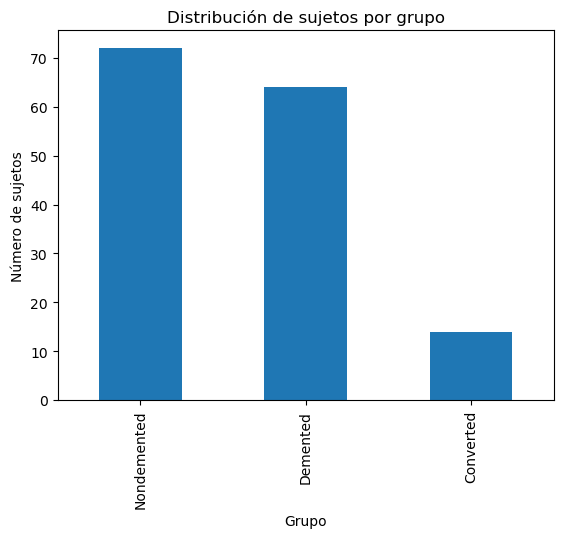

In [20]:
# Distribución de sujetos únicos por grupo
group_counts = (
    df_oasis2
    .drop_duplicates(subset="Subject ID")
    ["Group"]
    .value_counts()
)

group_counts.plot(
    kind="bar",
    title="Distribución de sujetos por grupo",
    xlabel="Grupo",
    ylabel="Número de sujetos"
)

El gráfico anterior representa **número de visitas por grupo**, no número de pacientes. Esta diferencia motivará que los análisis baseline seleccionen una única visita por sujeto y que el análisis longitudinal se construya posteriormente a nivel de paciente.

Además, el grupo `Converted` es especialmente pequeño, una característica que tendrá consecuencias importantes para la evaluación de los modelos de Machine Learning.


## 3. Distribución inicial de la edad

Se explora la distribución de la edad para conocer el rango representado en la cohorte y detectar posibles valores extremos antes de realizar comparaciones entre grupos.


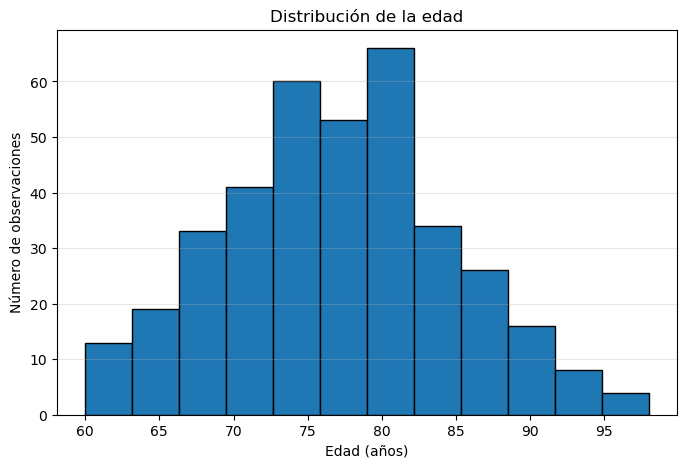

In [22]:
plt.figure(figsize=(8,5))

plt.hist(df_oasis2["Age"],
         bins=12,
         edgecolor="black")

plt.title("Distribución de la edad")
plt.xlabel("Edad (años)")
plt.ylabel("Número de observaciones")

plt.grid(axis="y", alpha=0.3)

plt.show()

Edad mínima: 60 años.
Edad máxima: 98 años.
La mayor concentración de pacientes se sitúa entre 70 y 85 años.
No se observan valores anómalos.
Esto confirma que el dataset representa una población anciana, coherente con el estudio del Alzheimer.

<Axes: xlabel='Group', ylabel='Age'>

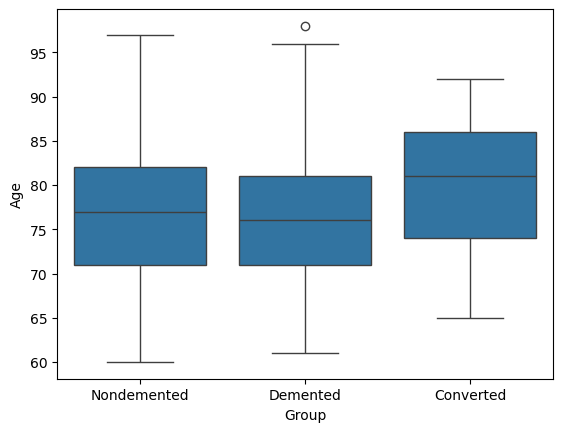

In [24]:
sns.boxplot(
    data=df_oasis2,
    x="Group",
    y="Age"
)

El histograma muestra una cohorte formada por adultos mayores, mientras que el boxplot permite observar el importante solapamiento de edad entre los grupos. Las comparaciones estadísticas formales se realizarán posteriormente utilizando la cohorte baseline.


## 4. Distribución por sexo

Se realiza una primera exploración de la distribución por sexo. Al igual que en el análisis de `Group`, estos recuentos corresponden inicialmente a visitas y no deben interpretarse todavía como prevalencias a nivel de paciente.


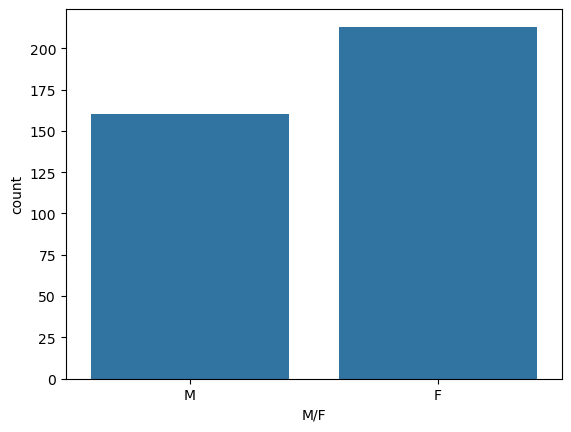

In [26]:
sns.countplot(x=df_oasis2["M/F"] )
plt.show()

In [28]:
df_oasis2.groupby(["Group","M/F"]).size()

Group        M/F
Converted    F       24
             M       13
Demented     F       60
             M       86
Nondemented  F      129
             M       61
dtype: int64

<Axes: xlabel='Group'>

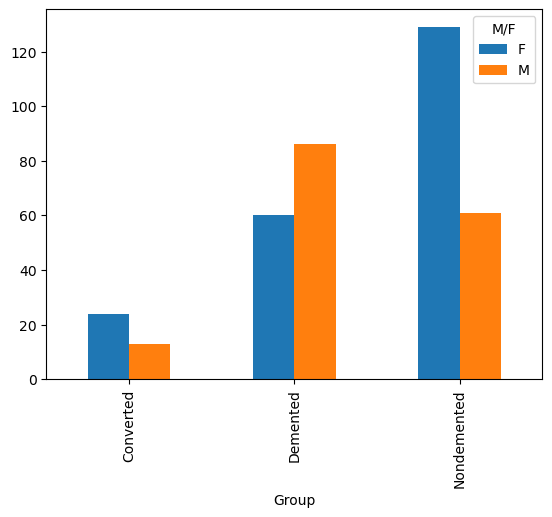

In [30]:
tabla = df_oasis2.groupby(["Group","M/F"]).size().unstack()

tabla.plot(kind="bar")

## 5. Próximos pasos

Esta exploración inicial permite establecer varias decisiones metodológicas para el resto del proyecto:

1. Separar claramente los análisis **por visita** de los análisis **por paciente**.
2. Utilizar la **primera visita** para estudiar las diferencias baseline.
3. Analizar posteriormente la evolución de los pacientes mediante un dataset longitudinal construido a nivel de sujeto.
4. Tener en cuenta el fuerte desbalance del grupo `Converted` durante la evaluación de Machine Learning.
5. Evitar utilizar identificadores como variables predictoras.

Los siguientes notebooks profundizarán en el EDA baseline y longitudinal mediante análisis estadísticos específicos.
